In [1]:
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [3]:
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"

detector = hub.load(MODEL_URL)

print("Model loaded successfully!")

Model loaded successfully!


In [4]:
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon",
    "bowl", "banana", "apple", "sandwich", "orange", "broccoli",
    "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet",
    "tv", "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

print("Number of classes:", len(COCO_CLASSES))

Number of classes: 80


In [5]:
def detect_objects_with_boxes(image_path, detector):

    # Read the image
    image = cv2.imread(image_path)

    # Check whether the image was read correctly
    if image is None:
        raise ValueError("Could not read image. Check the file path.")

    # Keep a clean copy for drawing
    orig_image = image.copy()

    # Convert image into a TensorFlow tensor
    input_tensor = tf.convert_to_tensor(image, dtype=tf.uint8)

    # Add batch dimension
    input_tensor = input_tensor[tf.newaxis, ...]

    # Run object detection
    detections = detector(input_tensor)

    # Extract the model outputs
    num_detections = int(detections["num_detections"].numpy())

    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = (
        detections["detection_classes"].numpy()[0].astype(np.int32)
    )
    detection_scores = detections["detection_scores"].numpy()[0]

    # Minimum confidence score
    confidence_threshold = 0.5

    # Get image height and width
    h, w, _ = orig_image.shape

    # Process each detection
    for i in range(num_detections):

        score = detection_scores[i]

        if score > confidence_threshold:

            # Get bounding box coordinates
            box = detection_boxes[i]
            y_min, x_min, y_max, x_max = box

            # Convert normalised coordinates to pixels
            x_min = int(x_min * w)
            x_max = int(x_max * w)
            y_min = int(y_min * h)
            y_max = int(y_max * h)

            # Get class ID
            class_id = detection_classes[i]

            # Convert class ID into class name
            if 1 <= class_id <= len(COCO_CLASSES):
                class_name = COCO_CLASSES[class_id - 1]
            else:
                class_name = "Unknown"

            # Create label
            label = f"{class_name}: {score:.2f}"

            # Draw bounding box
            cv2.rectangle(
                orig_image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )

            # Draw label above the box
            cv2.putText(
                orig_image,
                label,
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    # Return the image with detected objects
    return orig_image

Saving birds.webp to birds.webp


/tmp/ipykernel_685/1193524831.py:23: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  num_detections = int(detections["num_detections"].numpy())


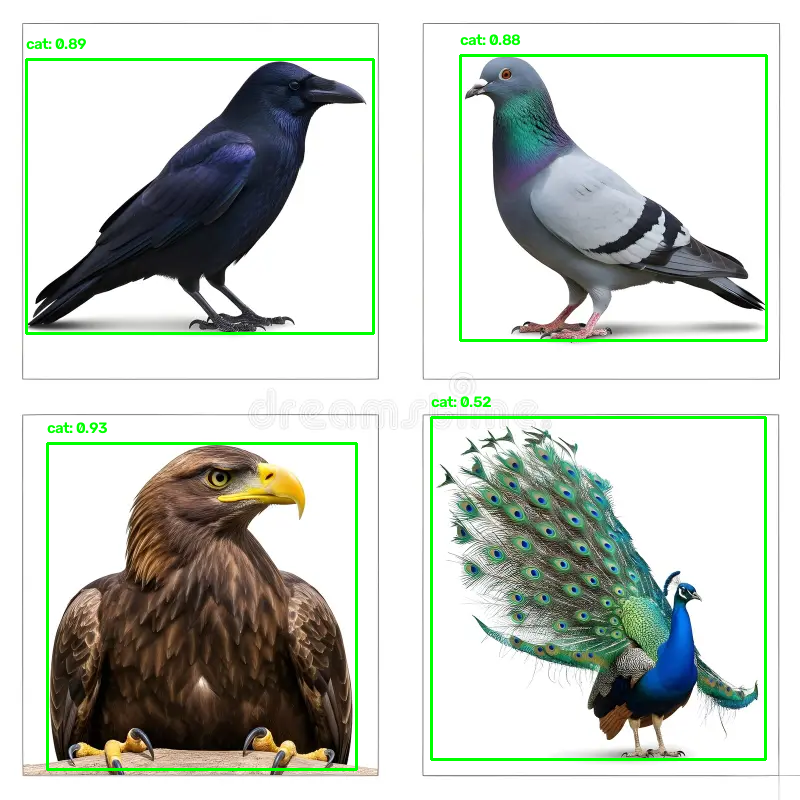

In [9]:
# Upload an image from your computer
uploaded = files.upload()

# Get the uploaded image filename
image_path = next(iter(uploaded))

# Run object detection
result_image = detect_objects_with_boxes(image_path, detector)

# Display the output image
cv2_imshow(result_image)